## Import Libraries

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.preprocessing import OneHotEncoder

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## Load the Dataset

In [2]:
df = pd.read_csv('../data/processed/rainfall_model_ready.csv')

In [3]:
df.head()

,SUBDIVISION,YEAR,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,...,Jun-Sep,Oct-Dec,annual_lag1,annual_lag2,annual_lag3,rolling_mean_3,annual_lag4,annual_lag5,rolling_mean_5,target
0,ANDAMAN & NICOBAR ISLANDS,1906,36.6,0.0,0.0,0.0,556.1,733.3,247.7,320.5,...,1465.8,475.9,2566.7,3079.6,2957.4,2867.900000,3520.7,3373.2,3099.52,3347.9
1,ANDAMAN & NICOBAR ISLANDS,1907,110.7,0.0,113.3,21.6,616.3,305.2,443.9,377.6,...,1327.1,1158.9,2534.4,2566.7,3079.6,2726.900000,2957.4,3520.7,2931.76,3576.4
2,ANDAMAN & NICOBAR ISLANDS,1915,45.0,56.7,33.3,40.9,170.2,334.7,269.0,317.2,...,1350.7,1044.5,2957.8,2365.8,2960.5,2761.366667,2687.2,2899.4,2774.14,2937.5
3,ANDAMAN & NICOBAR ISLANDS,1916,0.0,0.0,0.0,0.5,487.4,450.1,317.3,425.0,...,1753.6,696.0,2741.3,2957.8,2365.8,2688.300000,2960.5,2687.2,2742.52,2612.4
4,ANDAMAN & NICOBAR ISLANDS,1917,8.0,3.6,112.0,4.5,295.9,301.1,394.8,437.4,...,1605.1,583.3,2937.5,2741.3,2957.8,2878.866667,2365.8,2960.5,2792.58,3275.0


In [4]:
df.shape

(3874, 27)

In [5]:
print("Minimum year:", df['YEAR'].min())
print("Maximum year:", df['YEAR'].max())

print("\nSubdivisions:", df['SUBDIVISION'].nunique())

Minimum year: 1906
Maximum year: 2014

Subdivisions: 36


In [6]:
print(
    df.groupby('YEAR')['SUBDIVISION']
      .count()
      .head(10)
)

YEAR
1906    35
1907    35
1908    34
1909    34
1910    34
1911    34
1912    34
1913    34
1914    34
1915    35
Name: SUBDIVISION, dtype: int64


In [7]:
df = df.sort_values(
    ['YEAR', 'SUBDIVISION']
).reset_index(drop=True)

df.head()

,SUBDIVISION,YEAR,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,...,Jun-Sep,Oct-Dec,annual_lag1,annual_lag2,annual_lag3,rolling_mean_3,annual_lag4,annual_lag5,rolling_mean_5,target
0,ANDAMAN & NICOBAR ISLANDS,1906,36.6,0.0,0.0,0.0,556.1,733.3,247.7,320.5,...,1465.8,475.9,2566.7,3079.6,2957.4,2867.900000,3520.7,3373.2,3099.52,3347.9
1,ASSAM & MEGHALAYA,1906,9.7,59.2,88.4,263.5,271.3,388.4,541.8,585.9,...,1780.3,190.8,2790.7,2664.2,2544.6,2666.500000,2952.1,2498.7,2690.06,2521.3
2,BIHAR,1906,14.4,56.9,8.6,0.9,44.7,191.3,366.2,430.1,...,1106.3,33.3,1498.6,1269.7,1016.4,1261.566667,1206.2,952.4,1188.66,1126.4
3,CHHATTISGARH,1906,25.0,91.0,52.5,0.0,4.1,210.1,445.2,258.3,...,1155.9,66.1,1250.9,1492.4,1331.1,1358.133333,923.9,1386.9,1277.04,1308.8
4,COASTAL ANDHRA PRADESH,1906,3.9,23.5,9.9,2.3,11.0,252.6,155.8,241.1,...,776.4,194.4,795.0,860.1,1316.1,990.400000,1063.5,993.7,1005.68,817.9


In [8]:
feature_cols = [
    'annual_lag1',
    'annual_lag2',
    'annual_lag3',
    'annual_lag4',
    'annual_lag5',
    'rolling_mean_3',
    'rolling_mean_5'
]

target_col = 'target'

X = df[feature_cols]
y = df[target_col]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (3874, 7)
y shape: (3874,)


### Time Split

In [9]:
train_df = df[df['YEAR'] <= 2000].copy()

validation_df = df[
    (df['YEAR'] > 2000) &
    (df['YEAR'] <= 2008)
].copy()

test_df = df[
    (df['YEAR'] > 2008) &
    (df['YEAR'] <= 2014)
].copy()

print("Training:", train_df.shape)
print("Validation:", validation_df.shape)
print("Test:", test_df.shape)

Training: (3370, 27)
Validation: (288, 27)
Test: (216, 27)


In [10]:
print(
    "Train years:",
    train_df['YEAR'].min(),
    "to",
    train_df['YEAR'].max()
)

print(
    "Validation years:",
    validation_df['YEAR'].min(),
    "to",
    validation_df['YEAR'].max()
)

print(
    "Test years:",
    test_df['YEAR'].min(),
    "to",
    test_df['YEAR'].max()
)

Train years: 1906 to 2000
Validation years: 2001 to 2008
Test years: 2009 to 2014


### Create X and y for each split

In [11]:
X_train = train_df[feature_cols]
y_train = train_df[target_col]

X_validation = validation_df[feature_cols]
y_validation = validation_df[target_col]

X_test = test_df[feature_cols]
y_test = test_df[target_col]

print("X_train:", X_train.shape)
print("X_validation:", X_validation.shape)
print("X_test:", X_test.shape)

X_train: (3370, 7)
X_validation: (288, 7)
X_test: (216, 7)


### Create a simple Baseline

In [12]:
baseline_prediction = X_validation['annual_lag1']

In [13]:
baseline_mae = mean_absolute_error(
    y_validation,
    baseline_prediction
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        y_validation,
        baseline_prediction
    )
)

baseline_r2 = r2_score(
    y_validation,
    baseline_prediction
)

print("Baseline MAE:", baseline_mae)
print("Baseline RMSE:", baseline_rmse)
print("Baseline R²:", baseline_r2)

Baseline MAE: 253.03748477095522
Baseline RMSE: 340.21150865990705
Baseline R²: 0.8329592030317409


### Train Linear Regression

In [14]:
linear_model = LinearRegression()

linear_model.fit(
    X_train,
    y_train
)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [15]:
# Validate Predictions
linear_validation_pred = linear_model.predict(
    X_validation
)

In [16]:
# Evaluate
linear_mae = mean_absolute_error(
    y_validation,
    linear_validation_pred
)

linear_rmse = np.sqrt(
    mean_squared_error(
        y_validation,
        linear_validation_pred
    )
)

linear_r2 = r2_score(
    y_validation,
    linear_validation_pred
)

print("Linear Regression")
print("MAE:", linear_mae)
print("RMSE:", linear_rmse)
print("R²:", linear_r2)

Linear Regression
MAE: 224.26198826661025
RMSE: 291.2273444707588
R²: 0.8775979047381097


### Train Random Forest

In [17]:
rf_model = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train,
    y_train
)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [18]:
#Validate Predictions
rf_validation_pred = rf_model.predict(
    X_validation
)

In [19]:
#Evaluate
rf_mae = mean_absolute_error(
    y_validation,
    rf_validation_pred
)

rf_rmse = np.sqrt(
    mean_squared_error(
        y_validation,
        rf_validation_pred
    )
)

rf_r2 = r2_score(
    y_validation,
    rf_validation_pred
)

print("Random Forest")
print("MAE:", rf_mae)
print("RMSE:", rf_rmse)
print("R²:", rf_r2)

Random Forest
MAE: 233.93046871838007
RMSE: 302.7778908171008
R²: 0.8676960317464009


### Gradient Boosting

In [20]:
gb_model = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

gb_model.fit(
    X_train,
    y_train
)

,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.05
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",200
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'The function to measure the quality of a split. Supported criteria are""friedman_mse"" for the mean squared error with improvement score byFriedman, ""squared_error"" for mean squared error. The default value of""friedman_mse"" is generally the best as it can provide a betterapproximation in some cases... versionadded:: 0.18",'friedman_mse'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft

In [21]:
#Validate Prediction
gb_validation_pred = gb_model.predict(
    X_validation
)

In [22]:
#Evaluate
gb_mae = mean_absolute_error(
    y_validation,
    gb_validation_pred
)

gb_rmse = np.sqrt(
    mean_squared_error(
        y_validation,
        gb_validation_pred
    )
)

gb_r2 = r2_score(
    y_validation,
    gb_validation_pred
)

print("Gradient Boosting")
print("MAE:", gb_mae)
print("RMSE:", gb_rmse)
print("R²:", gb_r2)

Gradient Boosting
MAE: 234.86514779575907
RMSE: 297.74220641174924
R²: 0.8720602916120213


### Compare Models

In [23]:
results = pd.DataFrame({
    'Model': [
        'Baseline',
        'Linear Regression',
        'Random Forest',
        'Gradient Boosting'
    ],
    'MAE': [
        baseline_mae,
        linear_mae,
        rf_mae,
        gb_mae
    ],
    'RMSE': [
        baseline_rmse,
        linear_rmse,
        rf_rmse,
        gb_rmse
    ],
    'R2': [
        baseline_r2,
        linear_r2,
        rf_r2,
        gb_r2
    ]
})

results

,Model,MAE,RMSE,R2
0,Baseline,253.037485,340.211509,0.832959
1,Linear Regression,224.261988,291.227344,0.877598
2,Random Forest,233.930469,302.777891,0.867696
3,Gradient Boosting,234.865148,297.742206,0.872060


### Visualize Model Comparison

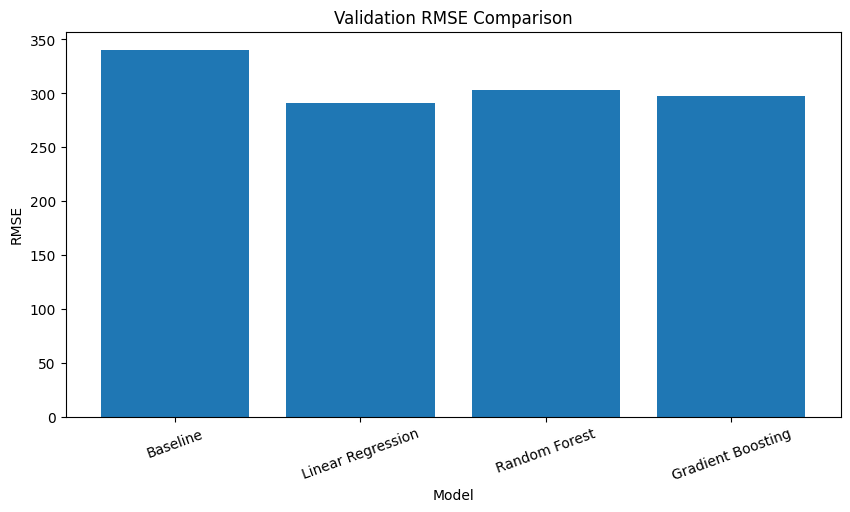

In [24]:
plt.figure(figsize=(10, 5))

plt.bar(
    results['Model'],
    results['RMSE']
)

plt.ylabel('RMSE')
plt.xlabel('Model')
plt.title('Validation RMSE Comparison')

plt.xticks(rotation=20)
plt.show()

### Feature Importance

In [25]:
importance = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': rf_model.feature_importances_
})

importance = importance.sort_values(
    'Importance',
    ascending=False
)

importance

,Feature,Importance
6,rolling_mean_5,0.854794
5,rolling_mean_3,0.063041
0,annual_lag1,0.023888
3,annual_lag4,0.014828
4,annual_lag5,0.014777
1,annual_lag2,0.014651
2,annual_lag3,0.014020


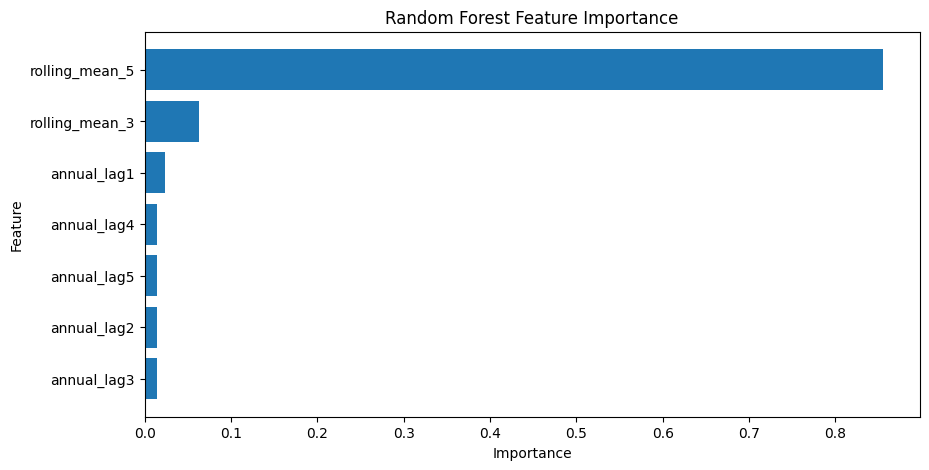

In [26]:
plt.figure(figsize=(10, 5))

plt.barh(
    importance['Feature'],
    importance['Importance']
)

plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Random Forest Feature Importance')

plt.gca().invert_yaxis()

plt.show()

### Best Model

In [27]:
best_model_name = results.loc[
    results['RMSE'].idxmin(),
    'Model'
]

print("Model with lowest validation RMSE:", best_model_name)

Model with lowest validation RMSE: Linear Regression


### Final Test Evaluation

In [28]:
validation_predictions = {
    'Baseline': baseline_prediction,
    'Linear Regression': linear_validation_pred,
    'Random Forest': rf_validation_pred,
    'Gradient Boosting': gb_validation_pred
}

test_models = {
    'Linear Regression': linear_model,
    'Random Forest': rf_model,
    'Gradient Boosting': gb_model
}

In [29]:
baseline_test_pred = X_test['annual_lag1']

test_results = []

In [30]:
test_results.append({
    'Model': 'Baseline',
    'MAE': mean_absolute_error(y_test, baseline_test_pred),
    'RMSE': np.sqrt(mean_squared_error(y_test, baseline_test_pred)),
    'R2': r2_score(y_test, baseline_test_pred)
})

In [31]:
for name, model in test_models.items():
    predictions = model.predict(X_test)

    test_results.append({
        'Model': name,
        'MAE': mean_absolute_error(y_test, predictions),
        'RMSE': np.sqrt(
            mean_squared_error(y_test, predictions)
        ),
        'R2': r2_score(y_test, predictions)
    })

In [32]:
test_results_df = pd.DataFrame(test_results)

test_results_df

,Model,MAE,RMSE,R2
0,Baseline,272.577875,370.596503,0.820902
1,Linear Regression,211.839813,289.060999,0.891040
2,Random Forest,226.968907,307.297467,0.876858
3,Gradient Boosting,220.773167,299.551880,0.882988


In [34]:
numeric_features = [
    'annual_lag1',
    'annual_lag2',
    'annual_lag3',
    'annual_lag4',
    'annual_lag5',
    'rolling_mean_3',
    'rolling_mean_5'
]

categorical_features = ['SUBDIVISION']

### Encoding

In [35]:
encoder = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False
)

In [36]:
X_train_cat = encoder.fit_transform(
    train_df[categorical_features]
)

X_validation_cat = encoder.transform(
    validation_df[categorical_features]
)

X_test_cat = encoder.transform(
    test_df[categorical_features]
)

In [37]:
X_train_num = train_df[numeric_features].values

X_validation_num = validation_df[numeric_features].values

X_test_num = test_df[numeric_features].values

In [38]:
X_train_exp2 = np.hstack([
    X_train_num,
    X_train_cat
])

X_validation_exp2 = np.hstack([
    X_validation_num,
    X_validation_cat
])

X_test_exp2 = np.hstack([
    X_test_num,
    X_test_cat
])

In [39]:
print("Training:", X_train_exp2.shape)
print("Validation:", X_validation_exp2.shape)
print("Test:", X_test_exp2.shape)

Training: (3370, 43)
Validation: (288, 43)
Test: (216, 43)


In [40]:
linear_model_exp2 = LinearRegression()

linear_model_exp2.fit(
    X_train_exp2,
    y_train
)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [41]:
linear_exp2_pred = linear_model_exp2.predict(
    X_validation_exp2
)

In [42]:
linear_exp2_mae = mean_absolute_error(
    y_validation,
    linear_exp2_pred
)

linear_exp2_rmse = np.sqrt(
    mean_squared_error(
        y_validation,
        linear_exp2_pred
    )
)

linear_exp2_r2 = r2_score(
    y_validation,
    linear_exp2_pred
)

print("Experiment 2 - Linear Regression")
print("MAE:", linear_exp2_mae)
print("RMSE:", linear_exp2_rmse)
print("R²:", linear_exp2_r2)

Experiment 2 - Linear Regression
MAE: 222.56728330871016
RMSE: 288.0026299241656
R²: 0.8802935755510675


In [43]:
linear_exp2_test_pred = linear_model_exp2.predict(
    X_test_exp2
)

In [44]:
linear_exp2_test_mae = mean_absolute_error(
    y_test,
    linear_exp2_test_pred
)

linear_exp2_test_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        linear_exp2_test_pred
    )
)

linear_exp2_test_r2 = r2_score(
    y_test,
    linear_exp2_test_pred
)

print("Experiment 2 - Test Results")
print("MAE:", linear_exp2_test_mae)
print("RMSE:", linear_exp2_test_rmse)
print("R²:", linear_exp2_test_r2)

Experiment 2 - Test Results
MAE: 213.44304215148648
RMSE: 289.1283970866267
R²: 0.8909892403494355


In [45]:
comparison = pd.DataFrame({
    'Experiment': [
        'Historical features only',
        'Historical features + SUBDIVISION'
    ],
    'MAE': [
        211.839813,
        linear_exp2_test_mae
    ],
    'RMSE': [
        289.060999,
        linear_exp2_test_rmse
    ],
    'R2': [
        0.891040,
        linear_exp2_test_r2
    ]
})

comparison

,Experiment,MAE,RMSE,R2
0,Historical features only,211.839813,289.060999,0.891040
1,Historical features + SUBDIVISION,213.443042,289.128397,0.890989


### Model Training Summary